In [ ]:
# Andrea Smith | 1996-2023 College Scorecard Exploratory Data Analysis

# Library installations
!pip install pandas matplotlib seaborn plotly geopandas
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import geopandas as gpd

# Set display and plot styles
pd.set_option('display.max_columns', None)
sns.set(style="whitegrid")


In [ ]:
# Load dataset
df = pd.read_csv("CollegeScorecardData_1996-2023.csv", low_memory=False)

# Preview
df.shape, df.columns[:20], df.head()


((189734, 1253),
 Index(['Unnamed: 0', 'FILE_DATE', 'UNITID', 'OPEID', 'OPEID6', 'INSTNM',
        'CITY', 'STABBR', 'ZIP', 'MAIN', 'NUMBRANCH', 'PREDDEG', 'HIGHDEG',
        'CONTROL', 'ST_FIPS', 'REGION', 'PCIP01', 'PCIP03', 'PCIP04', 'PCIP05'],
       dtype='object'),
    Unnamed: 0 FILE_DATE  UNITID     OPEID   OPEID6  \
 0           0   1996_97  100636  01230800  12308.0   
 1           1   1996_97  100654  00100200   1002.0   
 2           2   1996_97  100663  00105200   1052.0   
 3           3   1996_97  100672  00574900   5749.0   
 4           4   1996_97  100690  02503400  25034.0   
 
                                    INSTNM        CITY STABBR         ZIP  \
 0      Community College of the Air Force  Montgomery     AL  36114-3011   
 1                Alabama A & M University      Normal     AL       35762   
 2     University of Alabama at Birmingham  Birmingham     AL  35294-0110   
 3  ALABAMA AVIATION AND TECHNICAL COLLEGE       OZARK     AL       36360   
 4         

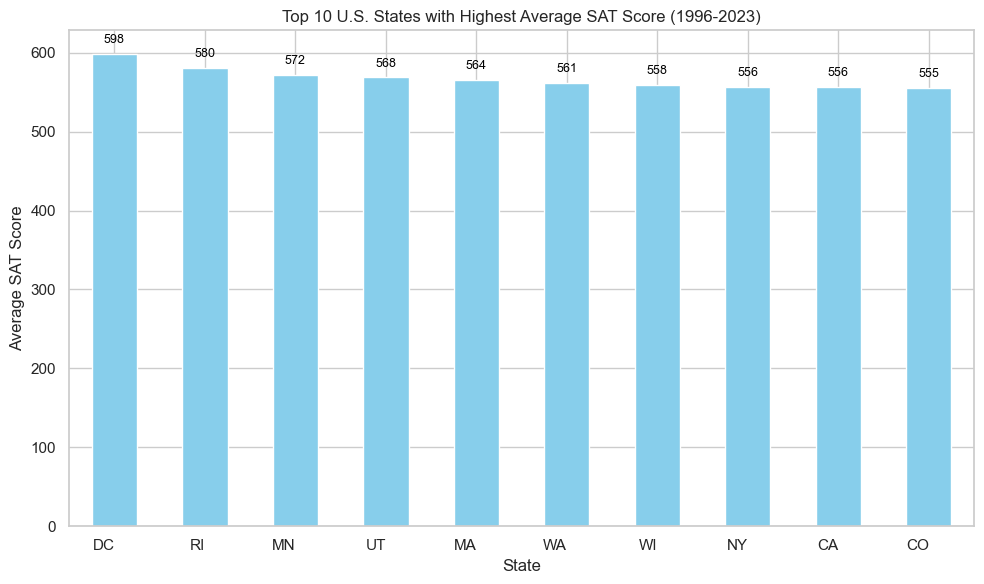

In [ ]:
# Visualization 1.) Bar Chart
import pandas as pd
import matplotlib.pyplot as plt

# Load the data (update the path as needed)
df_one = pd.read_csv("CollegeScorecardData_1996-2023.csv", usecols=['STABBR', 'SATVRMID', 'SATMTMID'])

# Drop rows with missing SAT scores
df_one = df_one.dropna(subset=['SATVRMID', 'SATMTMID'])

# Calculate average SAT score per institution
df_one['SAT_AVG'] = df_one[['SATVRMID', 'SATMTMID']].mean(axis=1)

# Group by state and compute mean SAT score
state_avg = df_one.groupby('STABBR')['SAT_AVG'].mean().sort_values(ascending=False).head(10)

# Plot bar chart
plt.figure(figsize=(10, 6))
ax = state_avg.plot(kind='bar', color='skyblue')
plt.title("Top 10 U.S. States with Highest Average SAT Score (1996-2023)")
plt.xlabel("State")
plt.ylabel("Average SAT Score")
plt.xticks(rotation=0, ha='right')

# Add the SAT score on top of each bar
for i, bar in enumerate(ax.patches):
    # Get the x and y coordinates of the bar
    x_val = bar.get_x() + bar.get_width() / 2
    y_val = bar.get_height()

    # Format the SAT score to an integer
    sat_score = int(y_val)

    # Add the SAT score text above the bar
    ax.text(x_val, y_val + 10, # +10 adds a small offset above the bar
            str(sat_score),
            ha='center',
            va='bottom', # Align text to the bottom of its bounding box
            color='black',
            fontsize=9)

plt.tight_layout()
plt.show()


In [ ]:
#Print Variable columns names to help with visualizations
print(df.columns.tolist())


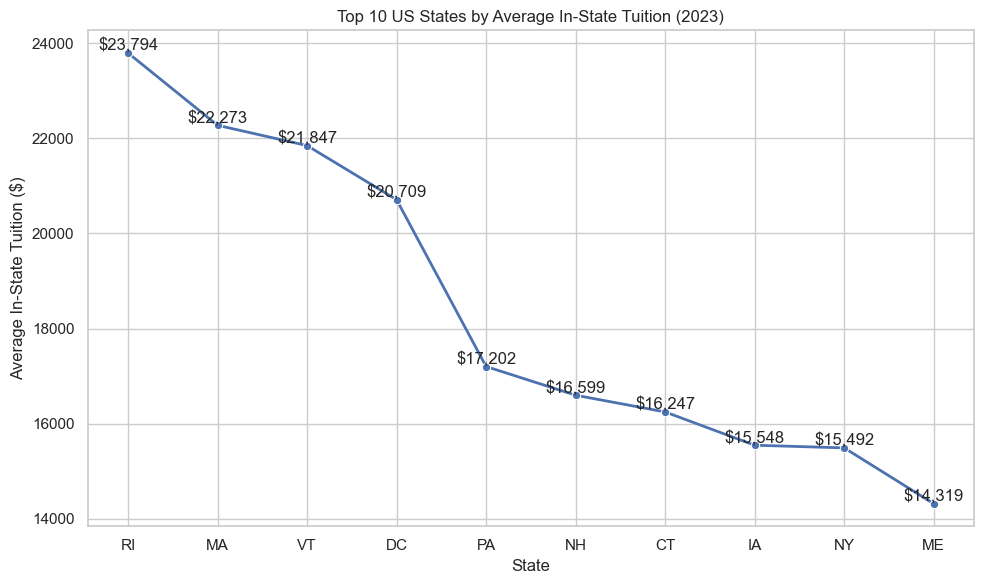

In [ ]:
# Visualization 2.) Line Chart
# Load the most recent cohort data
df_two = pd.read_csv("CollegeScorecardData_1996-2023.csv", usecols=["STABBR", "TUITIONFEE_IN"])

# Drop missing values
df_cost = df_two[df_two["TUITIONFEE_IN"].notnull()]

# Group by state and calculate mean tuition
state_tuition = df_cost.groupby("STABBR")["TUITIONFEE_IN"].mean().sort_values(ascending=False).head(10)

# Plot
plt.figure(figsize=(10, 6))
sns.lineplot(x=state_tuition.index, y=state_tuition.values, marker='o', linewidth=2)
# Add values at each point
for i, txt in enumerate(state_tuition.values):
    plt.text(state_tuition.index[i], txt, f'${txt:,.0f}', ha='center', va='bottom')

plt.title("Top 10 US States by Average In-State Tuition (2023)")
plt.xlabel("State")
plt.ylabel("Average In-State Tuition ($)")
plt.grid(True)
plt.tight_layout()
plt.show()



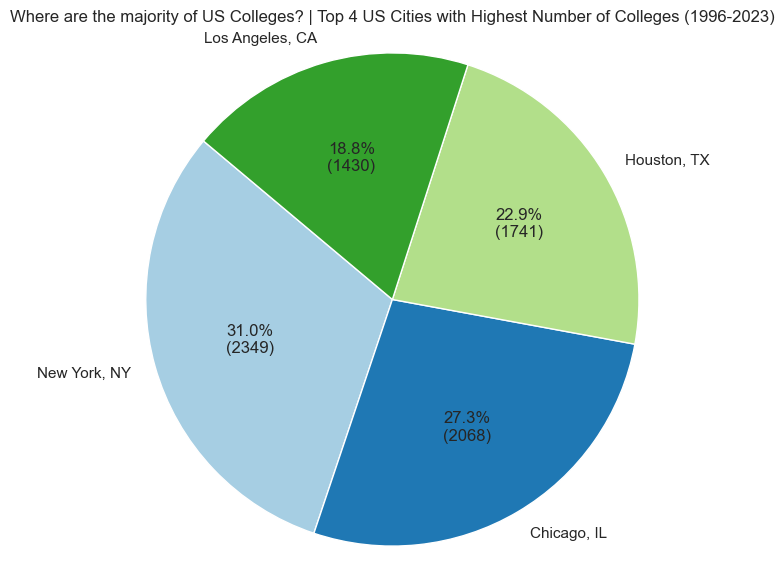

In [ ]:
# Visualization 3.) Pie Chart
import pandas as pd
import matplotlib.pyplot as plt

# Read the dataset
df = pd.read_csv("CollegeScorecardData_1996-2023.csv", usecols=['CITY'])

# Count the number of institutions per city and get the top 4
top_cities = df['CITY'].value_counts().nlargest(4)

# Optional: add state abbreviations if desired (manually for common cases)
city_labels = {
    'New York': 'New York, NY',
    'Los Angeles': 'Los Angeles, CA',
    'Chicago': 'Chicago, IL',
    'Houston': 'Houston, TX',
    'Phoenix': 'Phoenix, AZ',
    'Montgomery': 'Montgomery, AL',
    'Denver': 'Denver, CO',
    'Claremont': 'Claremont, CA'
}

# Replace labels with city + state if found in the mapping
renamed_index = [city_labels.get(city, city) for city in top_cities.index]

# Calculate the total number of institutions in the top 4 cities
total_top_cities_count = top_cities.sum()

# Define a function to format the autopct to show both percentage and count
def autopct_format_with_count(pct):
    # Calculate the actual count from the percentage
    absolute_count = int(round(pct/100.*total_top_cities_count))
    return f'{pct:.1f}%\n({absolute_count:d})'

# Plot pie chart
plt.figure(figsize=(7,7))
plt.pie(top_cities, labels=renamed_index, autopct=autopct_format_with_count, startangle=140, colors=plt.cm.Paired.colors)
plt.title('Where are the majority of US Colleges? | Top 4 US Cities with Highest Number of Colleges (1996-2023)')
plt.axis('equal')
plt.show()

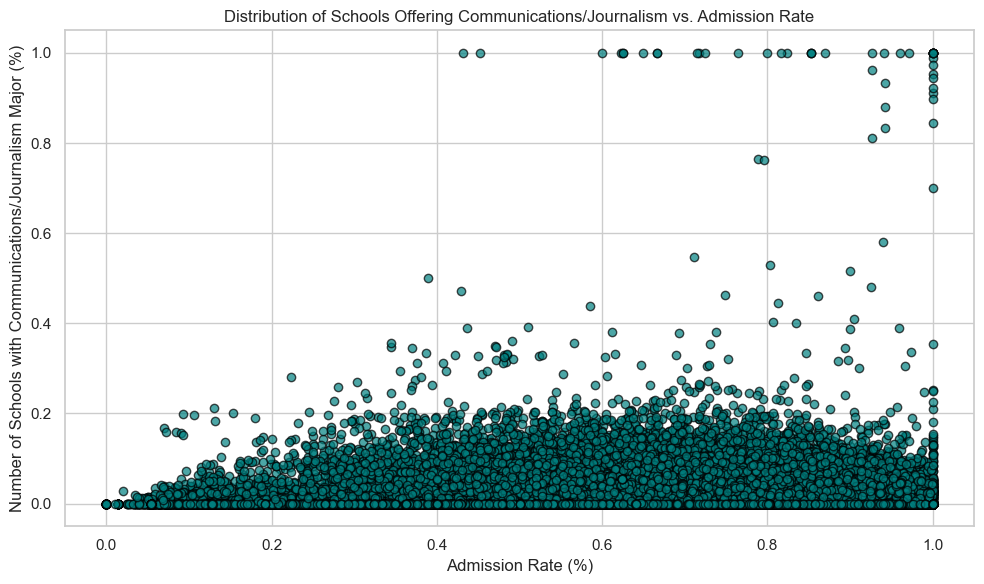

In [ ]:
#Visualization 4.) Scatterplot
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FormatStrFormatter

# Read the dataset (replace with actual file and column names)
df = pd.read_csv("CollegeScorecardData_1996-2023.csv", usecols=['PCIP09', 'ADM_RATE_ALL'])

# Drop rows with missing data
df = df.dropna(subset=['PCIP09', 'ADM_RATE_ALL'])

# Scatterplot
plt.figure(figsize=(10,6))
plt.scatter(df['ADM_RATE_ALL'], df['PCIP09'], alpha=0.7, color='teal', edgecolors='black')

plt.title('Distribution of Schools Offering Communications/Journalism vs. Admission Rate')
plt.xlabel('Admission Rate (%)')
plt.ylabel('Number of Schools with Communications/Journalism Major (%)')
plt.grid(True)
plt.tight_layout()
plt.show()


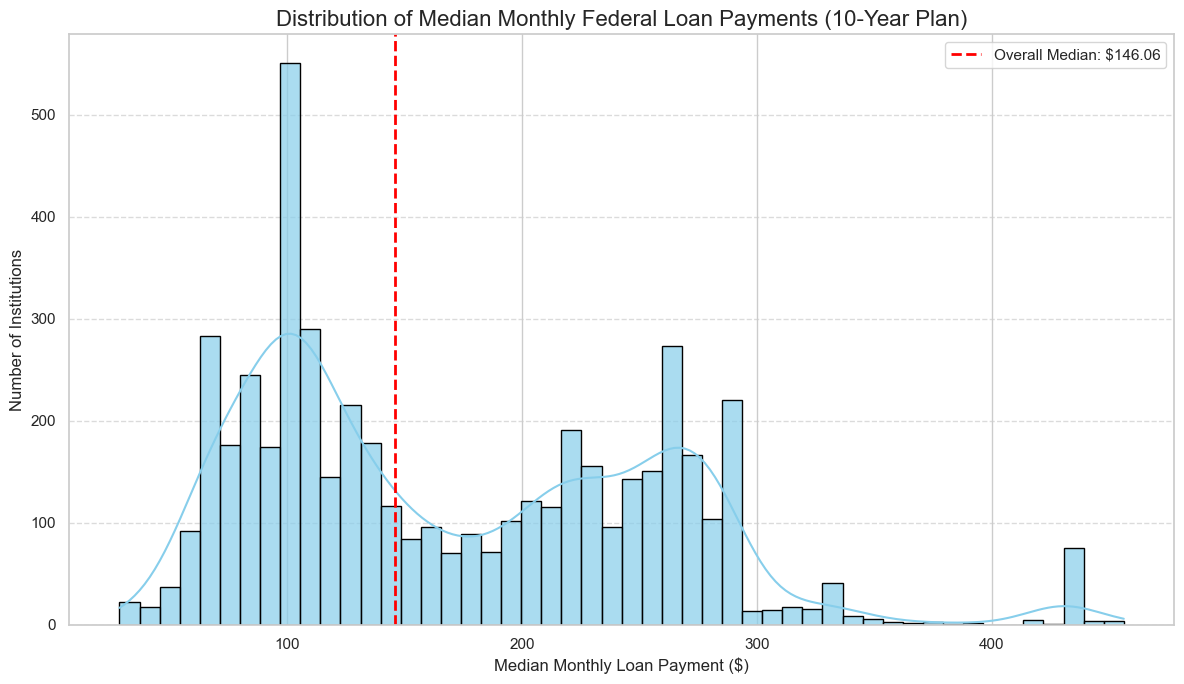

Total institutions with available median monthly loan payment data: 5004
Overall Median Monthly Loan Payment: $146.06
Average Monthly Loan Payment: $170.64
Standard Deviation of Monthly Loan Payment: $84.90
Range of Monthly Loan Payment: $28.79 - $456.09


In [ ]:
#Visualization 5.) Histogram
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset, specifically the relevant variable
# Assuming 'CollegeScorecardData_1996-2023.csv' is in the same directory.
df_loan_payment = pd.read_csv(
    "CollegeScorecardData_1996-2023.csv",
    usecols=["GRAD_DEBT_MDN10YR_SUPP"]
)

# Drop rows where the median monthly loan payment data is missing
# It's crucial to handle missing values as not all schools will have this data.
df_loan_payment_clean = df_loan_payment.dropna(
    subset=["GRAD_DEBT_MDN10YR_SUPP"]
)

# --- Create the Histogram ---
plt.figure(figsize=(12, 7))
sns.histplot(
    df_loan_payment_clean["GRAD_DEBT_MDN10YR_SUPP"],
    bins=50,  # Adjust the number of bins for desired granularity
    kde=True, # Overlay a Kernel Density Estimate to show the shape of the distribution
    color='skyblue',
    edgecolor='black',
    alpha=0.7
)

# Add titles and labels for clarity
plt.title(
    'Distribution of Median Monthly Federal Loan Payments (10-Year Plan)',
    fontsize=16
)
plt.xlabel(
    'Median Monthly Loan Payment ($)',
    fontsize=12
)
plt.ylabel(
    'Number of Institutions',
    fontsize=12
)

# Add grid for better readability
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add a vertical line for the overall median payment to highlight it
overall_median_payment = df_loan_payment_clean["GRAD_DEBT_MDN10YR_SUPP"].median()
plt.axvline(
    overall_median_payment,
    color='red',
    linestyle='dashed',
    linewidth=2,
    label=f'Overall Median: ${overall_median_payment:,.2f}'
)
plt.legend()

plt.tight_layout()
plt.show()

print(f"Total institutions with available median monthly loan payment data: {len(df_loan_payment_clean)}")
print(f"Overall Median Monthly Loan Payment: ${overall_median_payment:,.2f}")
print(f"Average Monthly Loan Payment: ${df_loan_payment_clean['GRAD_DEBT_MDN10YR_SUPP'].mean():,.2f}")
print(f"Standard Deviation of Monthly Loan Payment: ${df_loan_payment_clean['GRAD_DEBT_MDN10YR_SUPP'].std():,.2f}")
print(f"Range of Monthly Loan Payment: ${df_loan_payment_clean['GRAD_DEBT_MDN10YR_SUPP'].min():,.2f} - ${df_loan_payment_clean['GRAD_DEBT_MDN10YR_SUPP'].max():,.2f}")

In [ ]:
pip install squarify matplotlib

Note: you may need to restart the kernel to use updated packages.


C:\Users\Anansi Ghost\AppData\Local\Temp\ipykernel_6680\649821233.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_acceptance_rate_clean['ADM_RATE_SUPP_PCT'] = df_acceptance_rate_clean['ADM_RATE_SUPP'] * 100


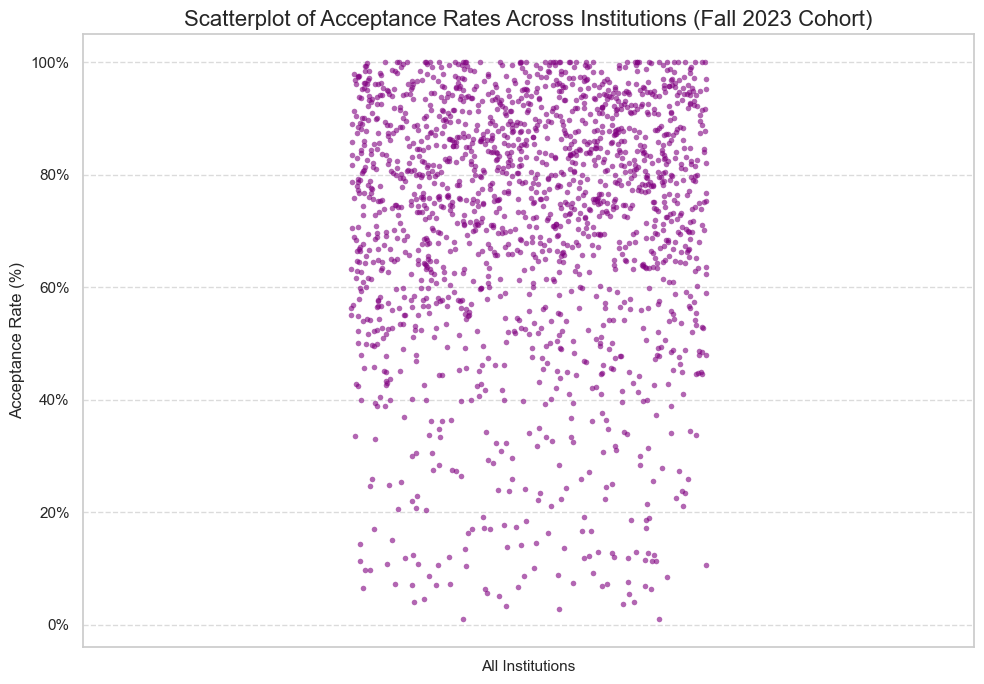

Total institutions with available acceptance rate data: 1766
Overall Median Acceptance Rate: 77.04%
Average Acceptance Rate: 72.04%
Range of Acceptance Rates: 1.00% - 100.00%


In [ ]:
#Visualization 6.) Scatterplot - Strip plot
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter # To format y-axis as percentages

# Load the dataset with the relevant variable
df_acceptance_rate = pd.read_csv(
    "CollegeScorecardData_1996-2023.csv",
    usecols=["ADM_RATE_SUPP"]
)

# Drop rows where the acceptance rate data is missing
# It's important to remove NaNs as they cannot be plotted.
df_acceptance_rate_clean = df_acceptance_rate.dropna(
    subset=["ADM_RATE_SUPP"]
)

# Convert acceptance rate to percentage (0-100 scale) for better readability
# Assuming 'ADM_RATE_SUPP' is a proportion between 0 and 1.
df_acceptance_rate_clean['ADM_RATE_SUPP_PCT'] = df_acceptance_rate_clean['ADM_RATE_SUPP'] * 100

# --- Create the Scatterplot (Strip Plot) ---
plt.figure(figsize=(10, 7))

# Use sns.stripplot to create a scatterplot of individual data points.
# We assign all data points to a single 'category' on the x-axis to show their distribution.
sns.stripplot(
    y=df_acceptance_rate_clean['ADM_RATE_SUPP_PCT'],
    x=['All Institutions'] * len(df_acceptance_rate_clean), # Dummy category for x-axis
    jitter=0.2, # Adds random noise to x-position to prevent overplotting
    color='purple', # Color of the points
    alpha=0.6, # Transparency of the points
    size=4 # Size of the points
)

# Add titles and labels for clarity
plt.title(
    'Scatterplot of Acceptance Rates Across Institutions (Fall 2023 Cohort)',
    fontsize=16
)
plt.xlabel('') # No meaningful x-label as it's a single category
plt.ylabel(
    'Acceptance Rate (%)',
    fontsize=12
)

# Format the y-axis ticks to display as percentages (e.g., 50% instead of 50.0)
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=100))

plt.grid(axis='y', linestyle='--', alpha=0.7) # Add a grid for better readability
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

# Print some descriptive statistics for context
print(f"Total institutions with available acceptance rate data: {len(df_acceptance_rate_clean)}")
print(f"Overall Median Acceptance Rate: {df_acceptance_rate_clean['ADM_RATE_SUPP_PCT'].median():.2f}%")
print(f"Average Acceptance Rate: {df_acceptance_rate_clean['ADM_RATE_SUPP_PCT'].mean():.2f}%")
print(f"Range of Acceptance Rates: {df_acceptance_rate_clean['ADM_RATE_SUPP_PCT'].min():.2f}% - {df_acceptance_rate_clean['ADM_RATE_SUPP_PCT'].max():.2f}%")